# Adirondack stereo: observed photographs to a dense geometric field


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：adirondack_stereo_depth_field

**观测 y：** left_image(1, 496, 718, 3)；right_image(1, 496, 718, 3)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 光轴深度Z与视差D。

**GT/参考来源：** GT来自独立测量；有效范围与测量误差限制需保留。

**由观测恢复目标：** 针孔双目投影，D=fB/Z-a。本地路径为 `main.reconstruct→cost_volume→solvers.aggregate(MGM)→depth_from_disparity`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 3, 5, 7, 9, 10, 11, 12, 13, 14（cell编号按文件内从0计）。章节包括：# Adirondack stereo: observed photographs to a dense geometric field；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 结构光测量有空缺与有限精度。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem
Two calibrated views constrain a surface through parallax. We reconstruct the complete left-camera optical-axis depth and its corresponding disparity. Occlusion makes correspondence unavailable in one image; texture and radiometry create additional ambiguity. This is the real author-distributed Q acquisition, not a resized demonstration or the entire 37-pair paper benchmark.

For a point with coordinates X,Y,Z in millimetres, the rectified pixel projections are

$$
u_L=fX/Z+c_L,\quad u_R=f(X-B)/Z+c_R,\quad D=u_L-u_R,\quad Z=fB/(D+a).
$$

Here f is focal length in pixels, B is baseline in mm, cL and cR are horizontal principal points, a=cR-cL, and D is left-minus-right disparity in pixels. X points right, Y down and Z into the scene. Depth means Z, not Euclidean camera distance. The coordinate offset must not be omitted.


In [1]:
from pathlib import Path
import os, sys, platform, time, json
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'data/raw_data.npz').is_file(): ROOT=ROOT.parent
if not (ROOT/'data/raw_data.npz').is_file(): raise RuntimeError('Run from task root or its notebooks directory')
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.main import reconstruct
from src.physics_model import depth_from_disparity
from src.visualization import agreement,save_review_figure,image_panel,point_cloud
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':12})
EXPORT=os.environ.get('IMAGING_REVIEW_EXPORT')
print({'python':sys.version,'numpy':np.__version__,'platform':platform.platform(),'executable':sys.executable})
left,right=load_observations(ROOT/'data/raw_data.npz')


{'python': '3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]', 'numpy': '2.4.6', 'platform': 'Windows-10-10.0.26200-SP0', 'executable': 'D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe'}


## 2. Data
Both native RGB arrays have shape496x718x3. Pixel values are unchanged from the acquired author images. The supplied initial-calibration rectification can retain small vertical residuals. No hidden target-based vertical correction is applied. Camera constants are f=1038.018pixels, B=176.252mm and a=53.271pixels.

Independent structured-light measurements, used below only for maintainer evaluation, have finite accuracy and incomplete availability. The main evaluation includes every available reference measurement, including occlusions. A separate nonocclusion label is used only to explain failure mechanisms. No reconstructed value determines either mask.


{'measured_reference_pixels': 354918, 'complete_output_pixels': 356128, 'native_shape': (496, 718, 3)}


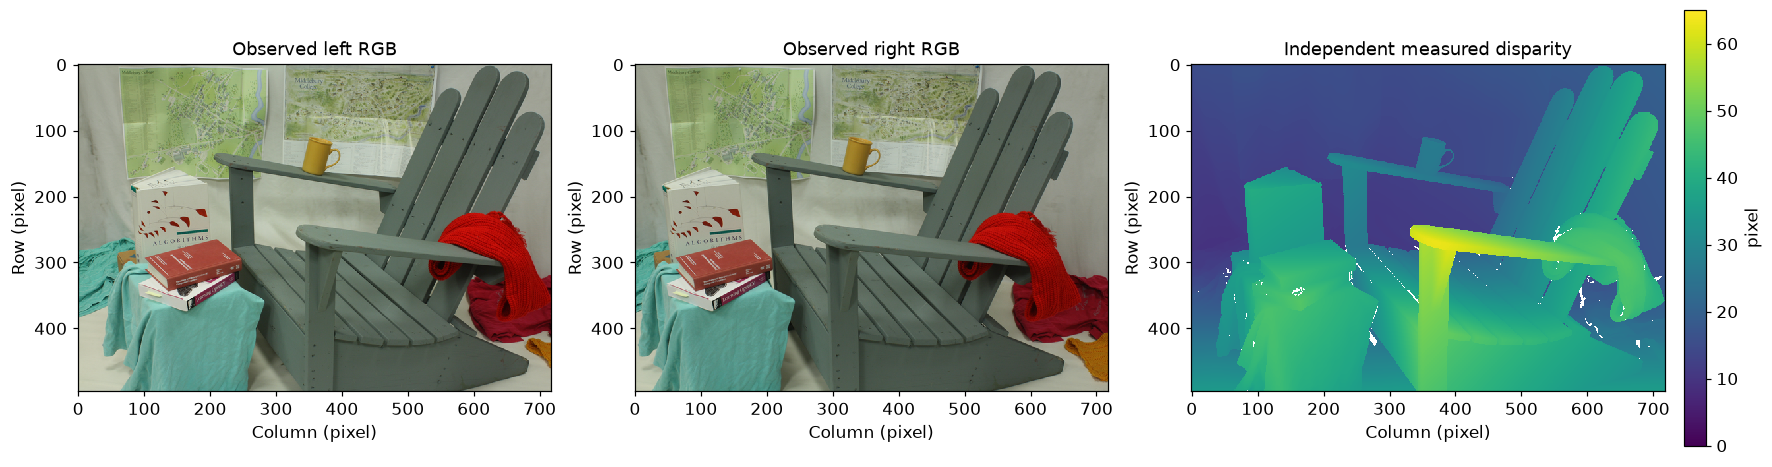

In [2]:
with np.load(ROOT/'evaluation/ground_truth.npz',allow_pickle=False) as data: truth=dict(data)
with np.load(ROOT/'notebooks/reference_outputs/upstream_method.npz',allow_pickle=False) as data: original=dict(data)
with np.load(ROOT/'notebooks/reference_outputs/upstream_comparisons.npz',allow_pickle=False) as data: original_comparisons=dict(data)
with np.load(ROOT/'test/fixtures/reference_availability.npz',allow_pickle=False) as data: nocc=data['nonoccluded']
mask=truth['valid_mask'][0];td=truth['disparity'][0];tz=truth['reconstruction'][0]
print({'measured_reference_pixels':int(mask.sum()),'complete_output_pixels':int(mask.size),'native_shape':left.shape})
fig,axes=plt.subplots(1,3,figsize=(16,4.2),layout='constrained')
image_panel(axes[0],left,'Observed left RGB')
image_panel(axes[1],right,'Observed right RGB')
image_panel(axes[2],np.ma.masked_where(~mask,td),'Independent measured disparity',limits=(0,65),unit='pixel')
save_review_figure(fig,'01_real_observations',{'left':left,'right':right,'measured_disparity':td,'measurement_available':mask},EXPORT)
plt.show()


## 3. Physics
The depth-disparity relation is nonlinear. A one-pixel error at a far surface has a different depth consequence than at a near surface. Independent pinhole tests in test/ establish the sign, baseline units and principal-point offset. Rectified photometric agreement is only approximate: a right-camera correspondence for a left pixel (u,v) is (u-D,v), and may be outside the acquired image or physically occluded.

The next calculation uses known geometric points and does not use the measured reference field. It is a geometry check, not an extra simulated benchmark acquisition.


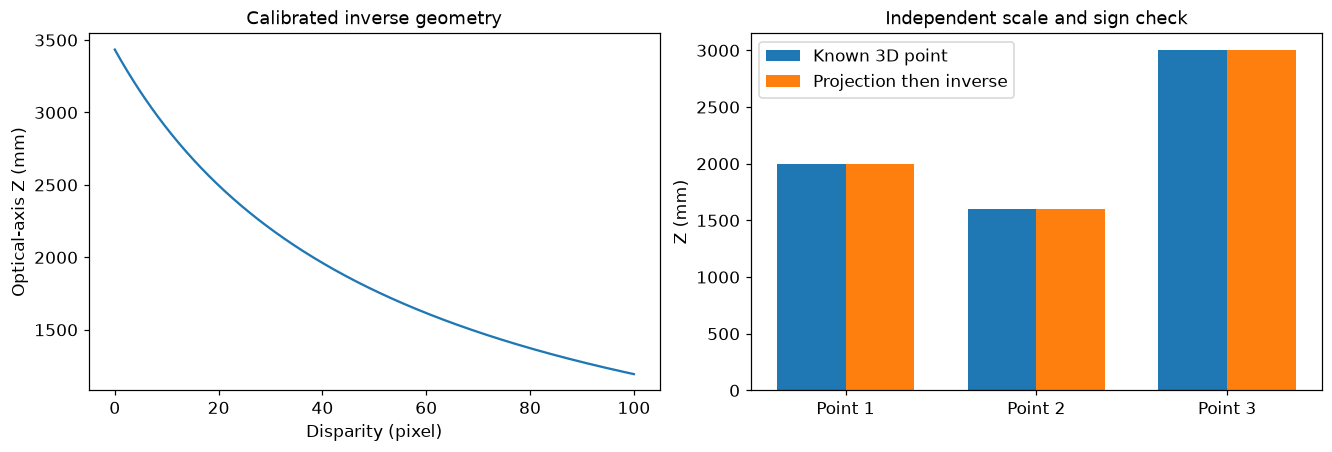

In [3]:
from src.physics_model import project_points
known=np.array([[100.,-30.,2000.],[-50.,90.,1600.],[0.,0.,3000.]])
uv_left,uv_right=project_points(known)
recovered=depth_from_disparity(uv_left[:,0]-uv_right[:,0])
assert np.allclose(recovered,known[:,2],rtol=1e-13,atol=0)
sample_d=np.linspace(0,100,500);sample_z=depth_from_disparity(sample_d)
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].plot(sample_d,sample_z);axes[0].set(xlabel='Disparity (pixel)',ylabel='Optical-axis Z (mm)',title='Calibrated inverse geometry')
axes[1].bar(np.arange(3)-.18,known[:,2],.36,label='Known 3D point')
axes[1].bar(np.arange(3)+.18,recovered,.36,label='Projection then inverse')
axes[1].set(xticks=np.arange(3),xticklabels=['Point 1','Point 2','Point 3'],ylabel='Z (mm)',title='Independent scale and sign check');axes[1].legend()
save_review_figure(fig,'02_pinhole_physics',{'known_xyz_mm':known,'left_uv':uv_left,'right_uv':uv_right,'recovered_z_mm':recovered,'sample_d':sample_d,'sample_z':sample_z},EXPORT)
plt.show()


## 4. Method
Census encodes72 strict RGB rank comparisons in a5x5 window. The source unary is the Hamming count divided by three packed words. Its CLI penalties8/32 are independently multiplied by three input channels, giving effective24/96. These two normalizations are preserved explicitly.

Let C(p,d) be unary cost at pixel p and native label d=uR-uL=-D, searched from-127 through0. For a predecessor accumulated-cost vector q, define

$$
m(q,d)=\min\big(q(d),\min(q(d-1),q(d+1))+P_1,\min_e q(e)+P_2\big)-\min_e q(e).
$$

P1=24 penalizes one-label differences, P2=96 penalizes larger changes, and e indexes all labels. Each MGM pass updates L(p,d)=C(p,d)+m(q,d)/2+m(r,d)/2 using two causal predecessor vectors q,r. Eight passes are added, and seven repeated unary copies are removed before label selection. All four original associated-neighbor boundary guards are preserved, even though two predecessors are used. Ties take the first ascending native label. This is an approximate discrete inverse, not proof of global energy optimality.

The primary reconstruction below is **actively computed from the two public images**. The separately loaded original result is used only for comparison.


{'fresh_primary_seconds': 9.538661200000206, 'original_parity_max_px': 0.0}


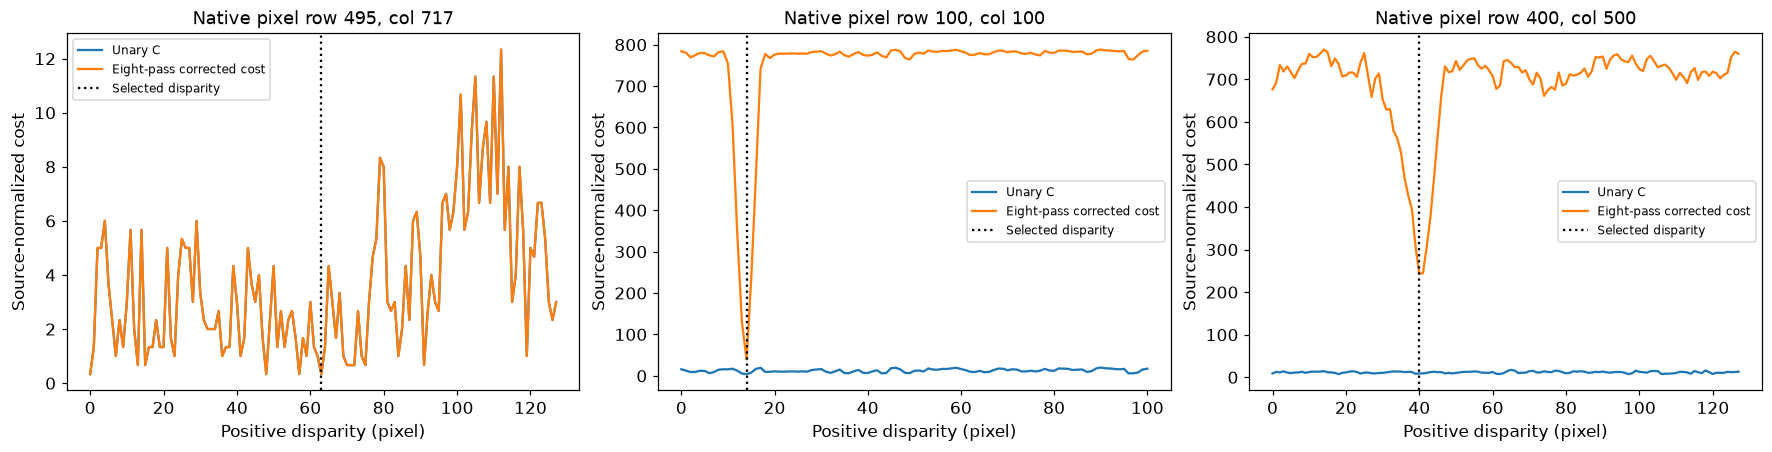

In [4]:
with np.load(ROOT/'test/fixtures/original_stages.npz',allow_pickle=False) as data: stage=dict(data)
start=time.perf_counter()
primary,diagnostics=reconstruct(ROOT/'data/raw_data.npz',capture_points=stage['points_yx'])
primary_seconds=time.perf_counter()-start
fresh_d=primary['disparity'][0];fresh_z=primary['reconstruction'][0]
assert np.max(np.abs(fresh_d-original['disparity']))<=1e-5
assert np.isfinite(fresh_d).all() and np.isfinite(fresh_z).all()
print({'fresh_primary_seconds':primary_seconds,'original_parity_max_px':float(np.max(abs(fresh_d-original['disparity'])))})
fig,axes=plt.subplots(1,3,figsize=(16,4),layout='constrained')
selected=[3,8,12];positive_labels=np.arange(127,-1,-1)
for ax,index in zip(axes,selected):
    unary=diagnostics['unary_samples'][index];aggregate=diagnostics['aggregate_samples'][index]
    ax.plot(positive_labels,unary,label='Unary C')
    ax.plot(positive_labels,aggregate,label='Eight-pass corrected cost')
    y,x=stage['points_yx'][index];ax.axvline(fresh_d[y,x],color='black',ls=':',label='Selected disparity')
    ax.set(title=f'Native pixel row {y}, col {x}',xlabel='Positive disparity (pixel)',ylabel='Source-normalized cost')
    ax.legend(fontsize=8)
save_review_figure(fig,'03_explicit_cost_aggregation',{'positive_labels':positive_labels,'points_yx':stage['points_yx'],'unary':diagnostics['unary_samples'],'aggregate':diagnostics['aggregate_samples']},EXPORT)
plt.show()


## 5. Results
Every comparison below executes the cleaned modules. The unchanged original CLI was independently run on the same images for SGM8, overcount-corrected SGM8, MGM4 and the two penalty settings. Their precomputed arrays remain explicitly labeled original. WTA is a fresh unary-only diagnostic. No missing method is filled with zeros or with an original reconstruction.

Scalar disparity maps use shared0..65pixel display limits and the depth map uses1500..3500mm; counts outside these color limits are printed and all values remain scored. Error-map colors are capped at+/-10pixels, with out-of-scale counts reported. The3D comparison uses common physical limits containing both full fields; display stride5 changes point rendering only.


{
  "fresh_metrics": {
    "MGM8": {
      "disparity": {
        "ncc": 0.9809551023342578,
        "nrmse": 0.11783727554088902,
        "bad1": 0.16715410320130283
      },
      "depth": {
        "ncc": 0.9961421250085033,
        "nrmse": 0.15156348394973018
      },
      "seconds": 9.538661200000206
    },
    "WTA": {
      "disparity": {
        "ncc": 0.8064213223482483,
        "nrmse": 0.6971829598271173,
        "bad1": 0.6933432511171594
      },
      "depth": {
        "ncc": 0.9619403096153554,
        "nrmse": 0.4806989944057932
      },
      "seconds": 3.5784863000008045
    },
    "SGM8": {
      "disparity": {
        "ncc": 0.9803640986237945,
        "nrmse": 0.11956707547040184,
        "bad1": 0.2050952614406708
      },
      "depth": {
        "ncc": 0.9962308925657356,
        "nrmse": 0.14981043238644212
      },
      "seconds": 7.5635274999949615
    },
    "ocSGM8": {
      "disparity": {
        "ncc": 0.9797065277544197,
        "nrmse": 0.1214601460

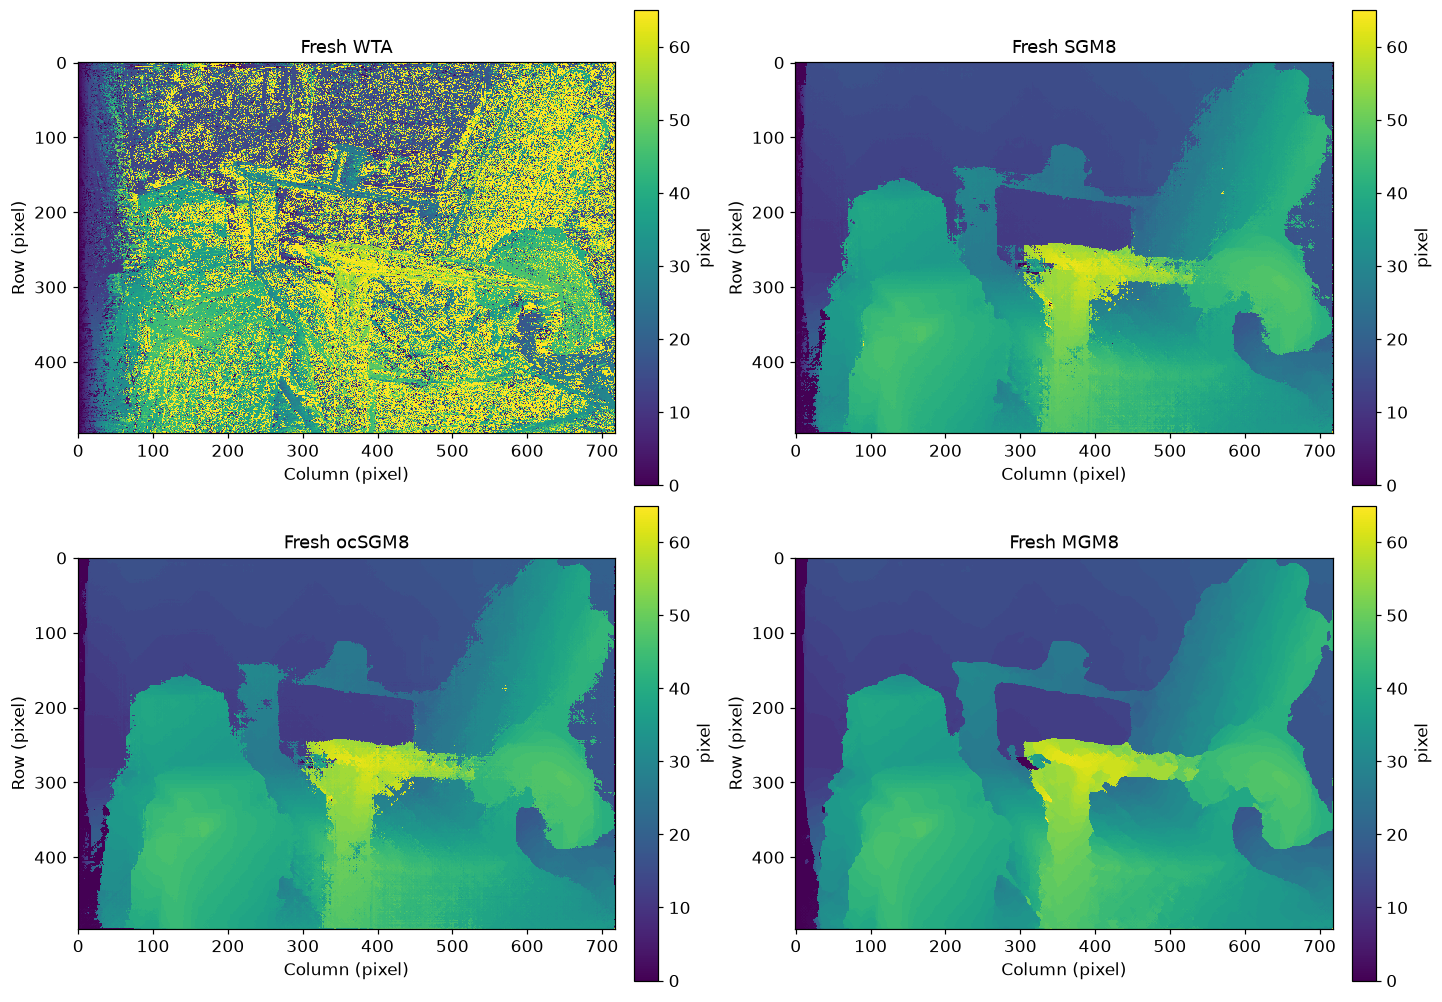

In [5]:
configs=[('WTA','wta',8,8,32,None),('SGM8','sgm',8,8,32,'sgm'),('ocSGM8','ocsgm',8,8,32,'ocsgm'),('MGM4','mgm',4,8,32,'mgm4'),('MGM8 soft','mgm',8,4,16,'mgm_soft'),('MGM8 strong','mgm',8,16,64,'mgm_strong')]
results={'MGM8':primary};runtimes={'MGM8':primary_seconds};parity={}
for name,method,ndir,p1,p2,upstream_key in configs:
    start=time.perf_counter();result,_=reconstruct(ROOT/'data/raw_data.npz',method,ndir,p1,p2)
    runtimes[name]=time.perf_counter()-start;results[name]=result
    if upstream_key:
        parity[name]=float(np.max(abs(result['disparity'][0]-original_comparisons[upstream_key])))
        assert parity[name]<=1e-5
measurements={name:{'disparity':agreement(result['disparity'][0],td,mask),'depth':agreement(result['reconstruction'][0],tz,mask,bad1_threshold=None),'seconds':runtimes[name]} for name,result in results.items()}
print(json.dumps({'fresh_metrics':measurements,'original_comparison_max_px':parity},indent=2))
print({'pixels_outside_shared_disparity_color_limits':{name:int(np.sum((result['disparity']<0)|(result['disparity']>65))) for name,result in results.items()},'primary_pixels_outside_depth_color_limits':int(np.sum((fresh_z<1500)|(fresh_z>3500)))})
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for ax,name in zip(axes.ravel(),['WTA','SGM8','ocSGM8','MGM8']):
    image_panel(ax,results[name]['disparity'][0],f'Fresh {name}',limits=(0,65),unit='pixel')
save_review_figure(fig,'04_published_method_comparisons',{name:results[name]['disparity'][0] for name in ['WTA','SGM8','ocSGM8','MGM8']},EXPORT)
plt.show()


{'errors_outside_display_scale_still_scored': 26709}


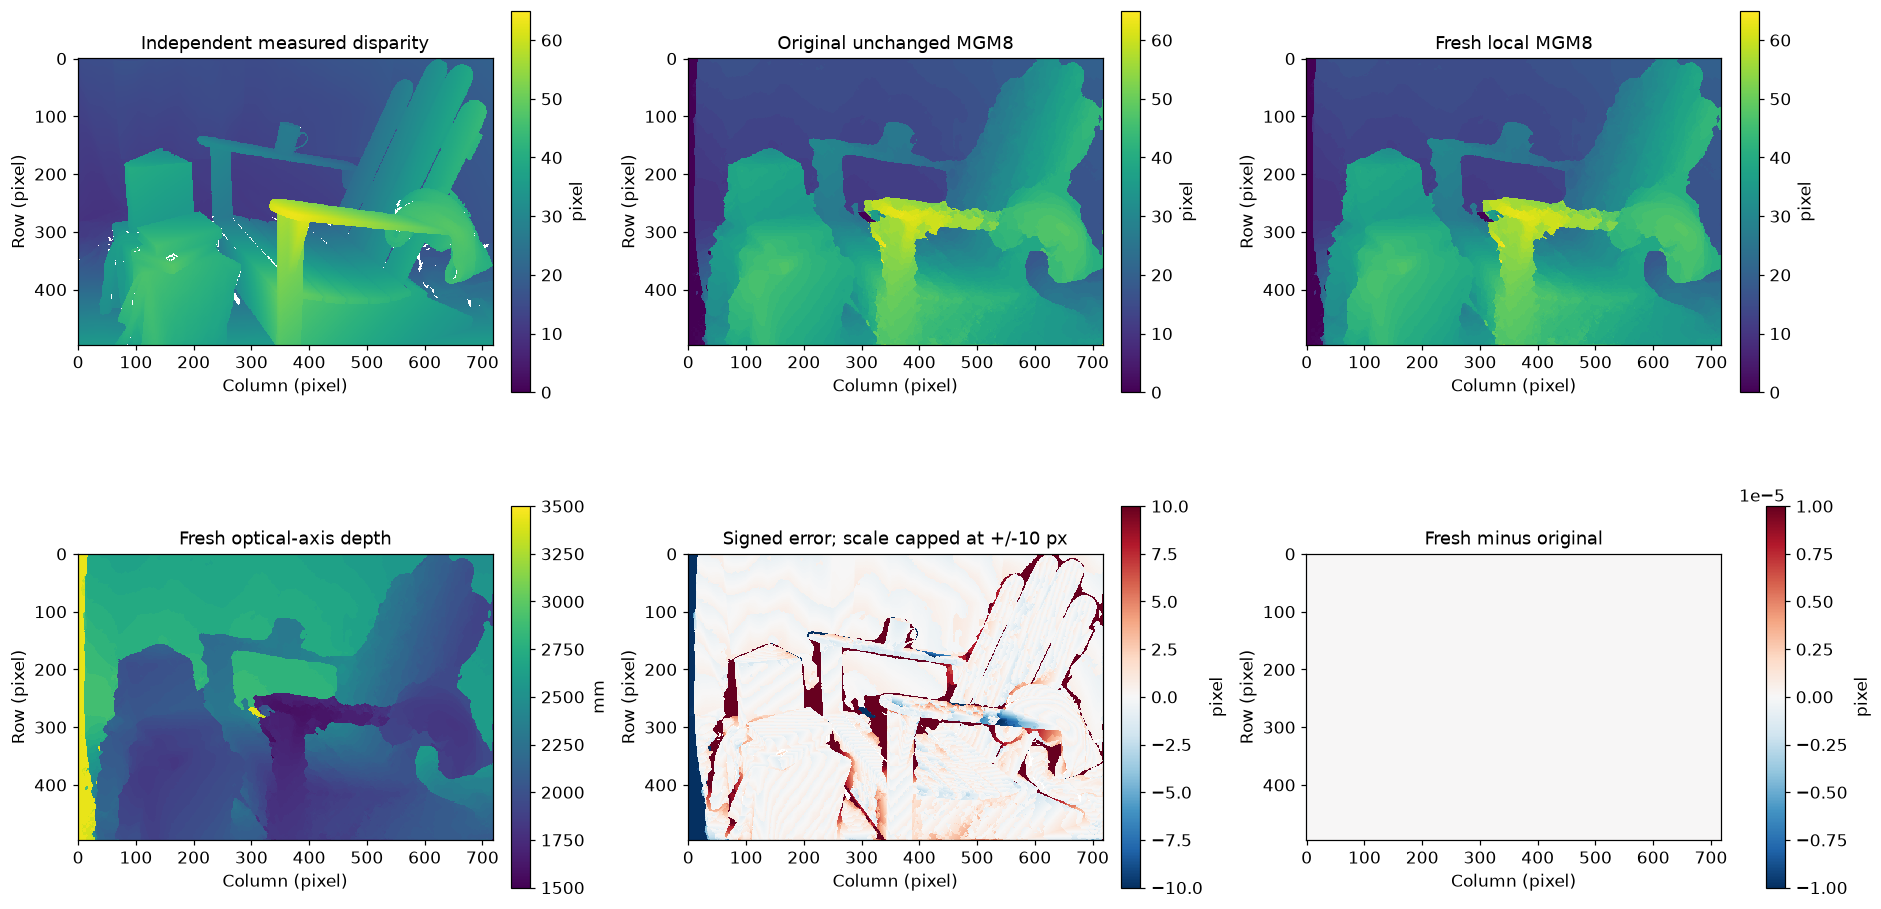

In [6]:
fig,axes=plt.subplots(2,3,figsize=(17,9),layout='constrained')
image_panel(axes[0,0],np.ma.masked_where(~mask,td),'Independent measured disparity',limits=(0,65),unit='pixel')
image_panel(axes[0,1],original['disparity'],'Original unchanged MGM8',limits=(0,65),unit='pixel')
image_panel(axes[0,2],fresh_d,'Fresh local MGM8',limits=(0,65),unit='pixel')
image_panel(axes[1,0],fresh_z,'Fresh optical-axis depth',limits=(1500,3500),unit='mm')
error=np.ma.masked_where(~mask,fresh_d-td)
image_panel(axes[1,1],error,'Signed error; scale capped at +/-10 px',limits=(-10,10),unit='pixel',cmap='RdBu_r')
image_panel(axes[1,2],fresh_d-original['disparity'],'Fresh minus original',limits=(-1e-5,1e-5),unit='pixel',cmap='RdBu_r')
print({'errors_outside_display_scale_still_scored':int(np.sum(abs(error.compressed())>10))})
save_review_figure(fig,'05_primary_and_independent_reference',{'fresh_disparity':fresh_d,'fresh_depth_mm':fresh_z,'original_disparity':original['disparity'],'measured_disparity':td,'valid_reference':mask,'signed_error':np.where(mask,fresh_d-td,np.nan)},EXPORT)
plt.show()


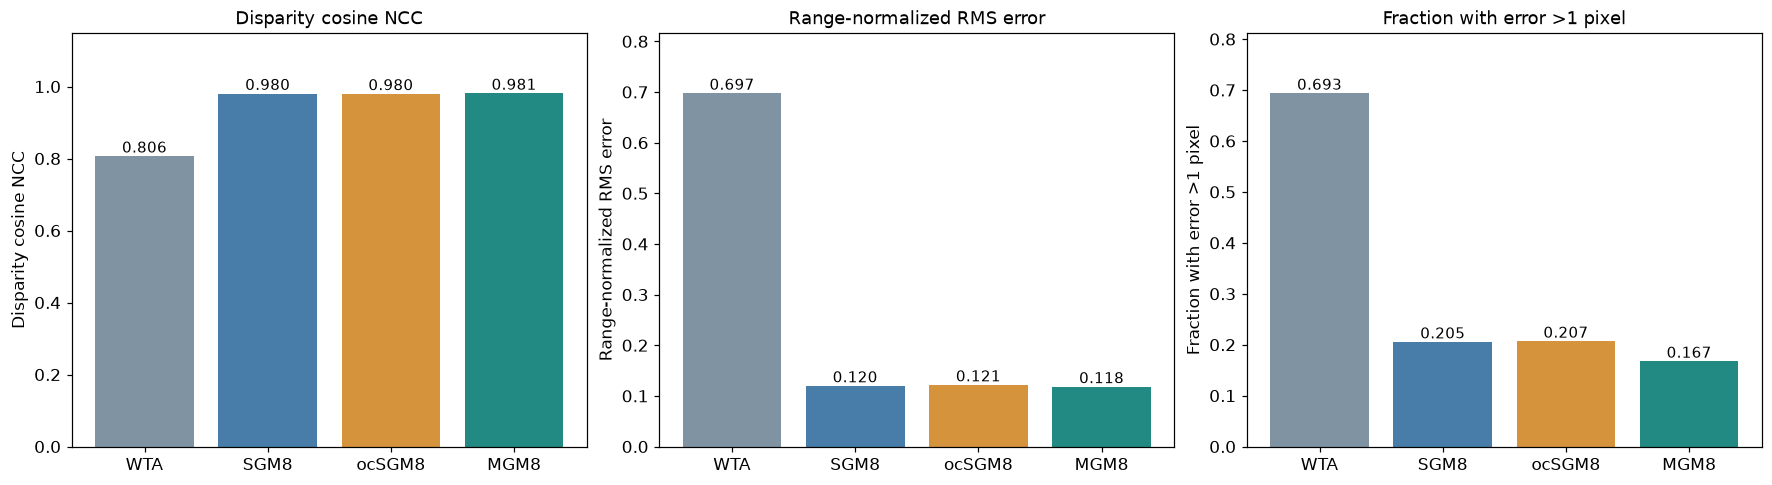

In [7]:
names=['WTA','SGM8','ocSGM8','MGM8'];positions=np.arange(len(names))
fig,axes=plt.subplots(1,3,figsize=(16,4.3),layout='constrained')
for ax,key,title in zip(axes,['ncc','nrmse','bad1'],['Disparity cosine NCC','Range-normalized RMS error','Fraction with error >1 pixel']):
    values=np.array([measurements[name]['disparity'][key] for name in names])
    ax.bar(positions,values,color=['#8093a2','#477da8','#d5933c','#238a83'])
    ax.set(xticks=positions,xticklabels=names,ylabel=title,title=title)
    for pos,value in zip(positions,values):ax.text(pos,value,f'{value:.3f}',ha='center',va='bottom',fontsize=10)
    ax.set_ylim(0,max(values)*1.17)
save_review_figure(fig,'06_metrics_all_measured_pixels',{'method_names':np.array(names),'metrics':np.array([[measurements[name]['disparity'][k] for k in ['ncc','nrmse','bad1']] for name in names]),'native_runtime_seconds':np.array([runtimes[name] for name in names])},EXPORT)
plt.show()


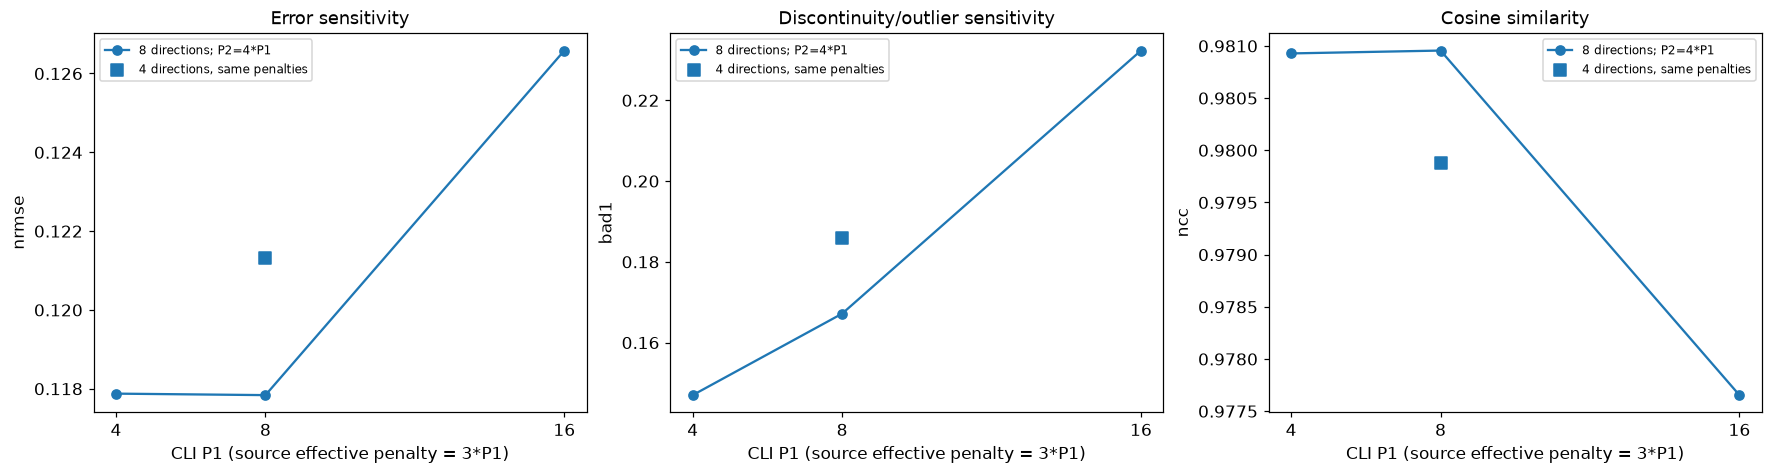

In [8]:
fig,axes=plt.subplots(1,3,figsize=(16,4.2),layout='constrained')
strength_names=['MGM8 soft','MGM8','MGM8 strong'];penalties=np.array([4,8,16])
for ax,key,title in zip(axes,['nrmse','bad1','ncc'],['Error sensitivity','Discontinuity/outlier sensitivity','Cosine similarity']):
    values=np.array([measurements[name]['disparity'][key] for name in strength_names])
    ax.plot(penalties,values,'o-',label='8 directions; P2=4*P1')
    ax.scatter([8],[measurements['MGM4']['disparity'][key]],marker='s',s=60,label='4 directions, same penalties')
    ax.set(xlabel='CLI P1 (source effective penalty = 3*P1)',ylabel=key,title=title,xticks=penalties)
    ax.legend(fontsize=8)
save_review_figure(fig,'07_fixed_observation_sensitivity',{'penalty_p1_cli':penalties,'strength_metrics':np.array([[measurements[name]['disparity'][key] for key in ['nrmse','bad1','ncc']] for name in strength_names]),'mgm4_metrics':np.array([measurements['MGM4']['disparity'][key] for key in ['nrmse','bad1','ncc']])},EXPORT)
plt.show()


{
  "All available": {
    "pixels": 354918,
    "bad1": 0.16715410320130283,
    "mae": 2.1048836708068848
  },
  "Nonoccluded": {
    "pixels": 325114,
    "bad1": 0.10679946111210221,
    "mae": 0.9778152108192444
  },
  "Occluded": {
    "pixels": 29804,
    "bad1": 0.8255267749295396,
    "mae": 14.399397850036621
  }
}


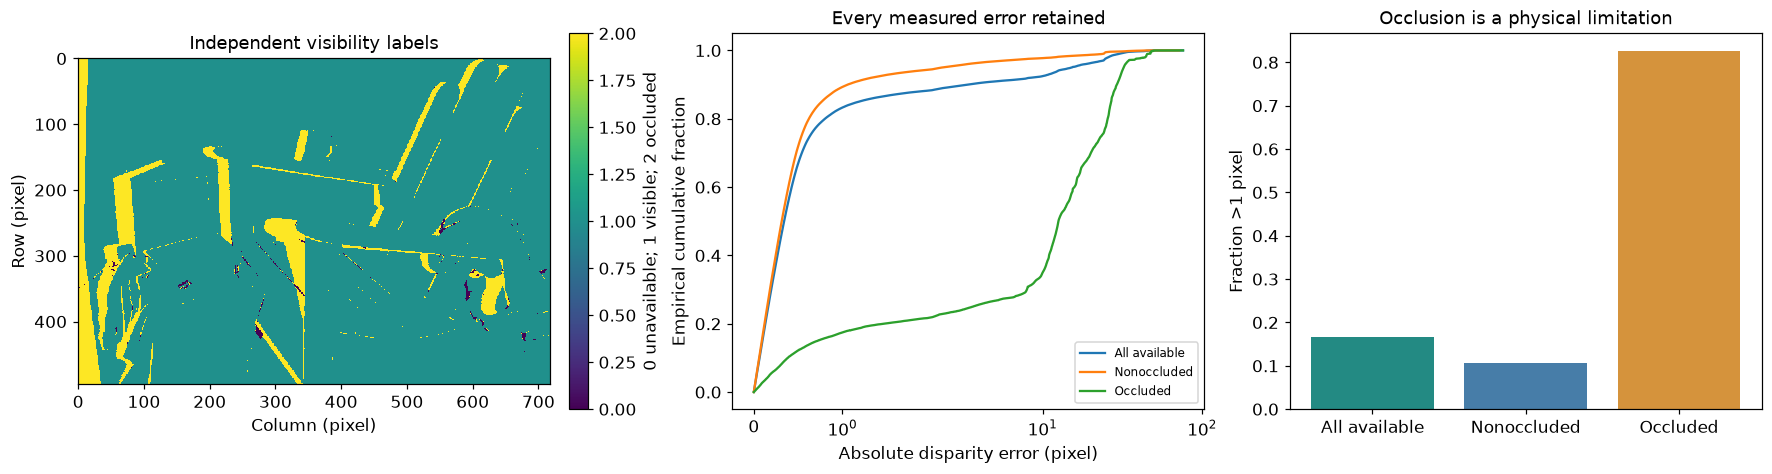

In [9]:
all_errors=np.abs(fresh_d[mask]-td[mask]);nonoccluded=mask & nocc;occluded=mask & ~nocc
groups={'All available':mask,'Nonoccluded':nonoccluded,'Occluded':occluded}
group_stats={name:{'pixels':int(support.sum()),'bad1':float(np.mean(np.abs(fresh_d[support]-td[support])>1)),'mae':float(np.mean(np.abs(fresh_d[support]-td[support])))} for name,support in groups.items()}
print(json.dumps(group_stats,indent=2))
fig,axes=plt.subplots(1,3,figsize=(16,4.2),layout='constrained')
image_panel(axes[0],np.where(mask,np.where(nocc,1,2),0),'Independent visibility labels',limits=(0,2),unit='0 unavailable; 1 visible; 2 occluded')
for name,support in groups.items():
    values=np.sort(np.abs(fresh_d[support]-td[support]))
    axes[1].plot(values,np.arange(1,len(values)+1)/len(values),label=name)
axes[1].set(xlabel='Absolute disparity error (pixel)',ylabel='Empirical cumulative fraction',title='Every measured error retained',xscale='symlog');axes[1].legend(fontsize=8)
axes[2].bar(np.arange(3),[group_stats[name]['bad1'] for name in groups],color=['#238a83','#477da8','#d5933c'])
axes[2].set(xticks=np.arange(3),xticklabels=list(groups),ylabel='Fraction >1 pixel',title='Occlusion is a physical limitation')
save_review_figure(fig,'08_occlusion_and_full_error_distribution',{'fresh_disparity':fresh_d,'measured_disparity':td,'available':mask,'nonoccluded':nocc,'group_bad1':np.array([group_stats[name]['bad1'] for name in groups]),'group_pixel_counts':np.array([group_stats[name]['pixels'] for name in groups])},EXPORT)
plt.show()


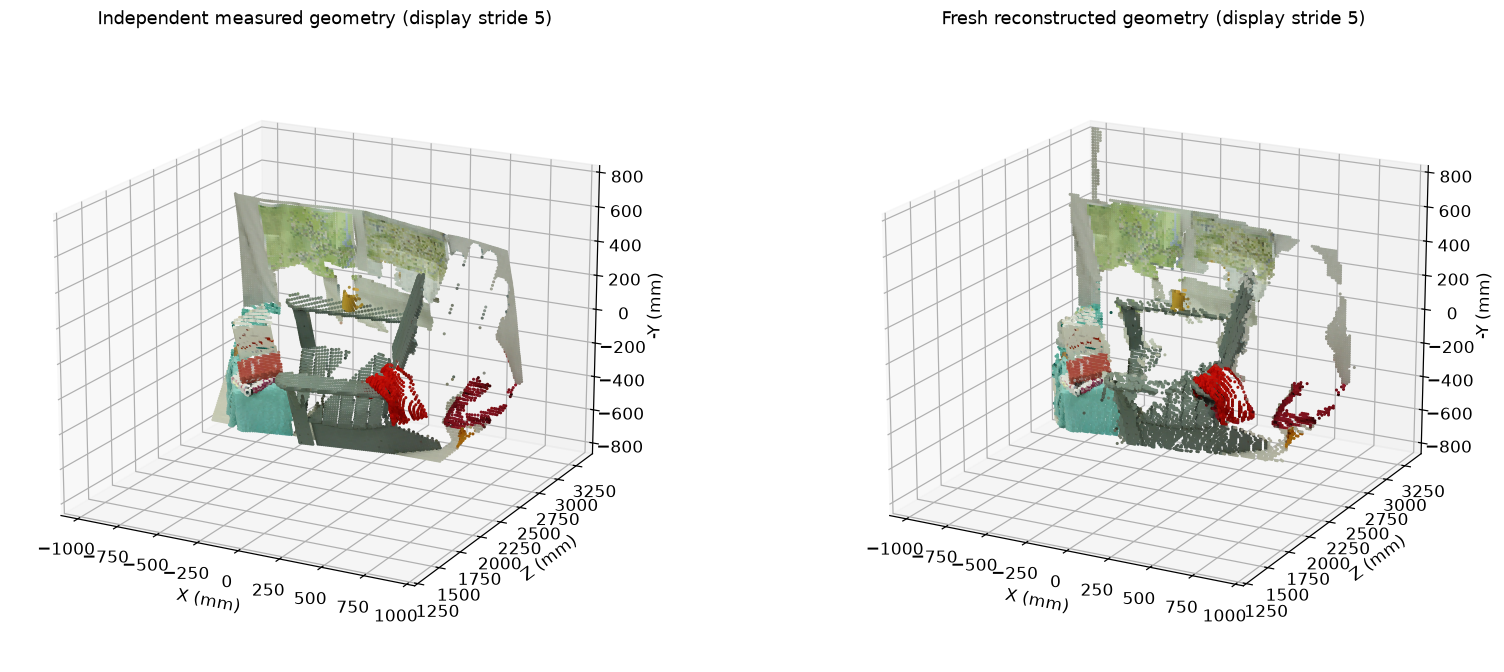

In [10]:
fig=plt.figure(figsize=(15,6),layout='constrained')
axes3d=[fig.add_subplot(121,projection='3d'),fig.add_subplot(122,projection='3d')]
point_cloud(axes3d[0],np.where(mask,tz,np.nan),left,'Independent measured geometry (display stride 5)')
point_cloud(axes3d[1],fresh_z,left,'Fresh reconstructed geometry (display stride 5)')
v,u=np.indices(fresh_z.shape);coordinates=[]
for depth,available in [(tz,mask),(fresh_z,np.ones(mask.shape,bool))]:
    coordinates.append(np.stack([(u-322.037)*depth/1038.018,depth,-(v-243.393)*depth/1038.018],axis=-1)[available])
all_coordinates=np.concatenate(coordinates);low=all_coordinates.min(axis=0);high=all_coordinates.max(axis=0)
span=high-low;low-=.02*span;high+=.02*span
for ax in axes3d:
    ax.set(xlim=(low[0],high[0]),ylim=(low[1],high[1]),zlim=(low[2],high[2]))
    ax.set_box_aspect(high-low)
save_review_figure(fig,'09_calibrated_textured_geometry',{'fresh_depth_mm':fresh_z,'measured_depth_mm':tz,'available':mask,'rgb':left,'display_stride':np.array(5)},EXPORT)
plt.show()
if EXPORT:
    Path(EXPORT,'measurements.json').write_text(json.dumps({'fresh':measurements,'comparison_parity_max_px':parity,'occlusion':group_stats,'source_primary':'Original independent CLI capture, not a cached paper report'},indent=2),encoding='utf8')
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_measurements.npz',method_names=np.array(list(results)),metrics=np.array([[measurements[name]['disparity'][k] for k in ['ncc','nrmse','bad1']] for name in results]),seconds=np.array([runtimes[name] for name in results]))


## 6. Conclusion
The complete two-view acquisition was actively reconstructed with explicit local Census costs, directional inverse updates and calibrated triangulation. Stage and full-field agreement with independent original execution establish faithful numerical extraction. Independent structured-light measurements separately assess geometric quality; large native errors at occlusions and weak textures remain visible and counted. Display strides, masks and color scales affect visualization only, not primary evaluation.

The method is approximate and the reference measurement has finite accuracy. This one real author-provided pair is not a full paper benchmark reproduction or evidence of general robustness. Parameter and method comparisons above are actually computed diagnostics. Source revision, data hashes, exact commands, failed checks and final native nbconvert evidence are recorded in test/validation.md.
